In [1]:
# ==========================================
# ENVIRONMENT SETUP & INSTALLATIONS
# ==========================================
# Install and import libraries
%pip install geopandas fiona pyarrow fastparquet osmnx networkx -q

import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
import os
import json
import gc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 5.0 MB/s eta 0:00:00


In [ ]:
# ==========================================
# LOCATE THE PROJECT FOLDER
# ==========================================
# Finds the cloned repository (the folder that contains 03_scripts).
# Works locally, in Colab and elsewhere. Set the PROJECT_ROOT environment variable to override.
import os
from pathlib import Path

def find_project_root():
    if os.environ.get("PROJECT_ROOT"):
        return Path(os.environ["PROJECT_ROOT"])
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "03_scripts").is_dir():
            return folder
    colab_clones = sorted(Path("/content").glob("*/03_scripts"))
    if colab_clones:
        return colab_clones[0].parent
    raise FileNotFoundError("Project folder not found. Run the notebook from inside the cloned repository, or set PROJECT_ROOT.")

PROJECT_ROOT = str(find_project_root())
print(f"Project folder: {PROJECT_ROOT}")

In [ ]:
# ==========================================
# DO NOT RUN THIS AGAIN - DATA LOCKED TO 26 JUNE 2026 FOR METHODOLOGY
# THE 26 JUNE 2026 GRAPHML FILE IS ALREADY IN THE OUTPUT FOLDER AND A COPY
# ALREADY ARCHIVED
# RE-RUNNING THIS CELL WILL OVERWRITE IT WITH THE DAY'S VERSION
# OSM DATA ARE UPDATED REGULARLY
# NETWORK ANALYSIS (OSM GRAPH CONSTRUCTION)
# ==========================================
# DOWNLOAD DISABLED: the original download code is kept below as comments.
# The active lines at the end load the locked 26 June 2026 graphml into G
# and record its topology in the attrition log, as the original run did.
# import osmnx as ox
# import geopandas as gpd
# import networkx as nx
# from shapely.ops import unary_union
# import os
# import json

# Define Paths
# BASE_DIR = PROJECT_ROOT
# buffer_path = os.path.join(BASE_DIR, '01_raw_data/Stations_and_2000m_Buffer/All_Stations_2000m_Buffer.geojson')
# log_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')
# output_dir = os.path.join(BASE_DIR, '02_processed_data/04_network')

# Load and Prepare the Bounding Polygon
# gdf_buffer = gpd.read_file(buffer_path)

# Unify buffers into a single geometry to avoid API errors
# combined_buffer = unary_union(gdf_buffer.geometry)

# Reproject for OSM API (WGS84 / EPSG:4326)
# buffer_wgs84 = gpd.GeoSeries([combined_buffer], crs="EPSG:27700").to_crs("EPSG:4326")

# print("Downloading pedestrian network from OSM...")
# Retain_all=True preserves the disconnected town networks
# G = ox.graph_from_polygon(buffer_wgs84.iloc[0], network_type='walk', retain_all=True)

# Reproject Graph back to BNG (EPSG:27700) for analysis
# print("Projecting graph to BNG (27700)...")
# G = ox.project_graph(G, to_crs="EPSG:27700")

# Extract and Print Topological Evidence
# num_components = nx.number_connected_components(G.to_undirected())
# num_nodes = len(G.nodes)
# num_edges = len(G.edges)

# print("-" * 30)
# print("TOPOLOGICAL EVIDENCE:")
# print(f"Connected Components: {num_components}")
# print(f"Total Nodes: {num_nodes}")
# print(f"Total Edges: {num_edges}")
# print("-" * 30)

# Update Attrition Log
#  network_log_entry = {
#     "Part_4_Network_Analysis": {
#         "Graph_Construction": {
#             "01_Connected_Components": num_components,
#             "02_Total_Nodes": num_nodes,
#             "03_Total_Edges": num_edges,
#             "Note": "Graph topologically validated with retain_all=True to preserve all disjoint station buffers."
#         }
#     }
# }

# Ensure log directory exists
# os.makedirs(os.path.dirname(log_path), exist_ok=True)

# Update log file
# if os.path.exists(log_path):
#     with open(log_path, 'r+') as f:
#         try:
#             data = json.load(f)
#         except json.JSONDecodeError:
#             data = {}
#         if "Part_4_Network_Analysis" not in data:
#             data["Part_4_Network_Analysis"] = {}
#         data["Part_4_Network_Analysis"].update(network_log_entry["Part_4_Network_Analysis"])
#         f.seek(0)
#         json.dump(data, f, indent=4)
#         f.truncate()
#     print("Log updated: Topology metrics recorded.")

# Ensure output directory exists
# os.makedirs(output_dir, exist_ok=True)

# 1. Export as GraphML for network routing scripts
# ox.save_graphml(G, filepath=os.path.join(output_dir, 'devon_walk_network.graphml'))
# print("Successfully exported network topology to devon_walk_network.graphml")

# 2. Convert graph to GeoDataFrames and export as a GeoPackage for QGIS mapping
# print("Converting network graph to spatial layers (this may take a moment)...")
# nodes, edges = ox.graph_to_gdfs(G)

# Save edges (the streets/footpaths) and nodes (the junctions) as distinct layers
# edges_path = os.path.join(output_dir, 'devon_walk_network.gpkg')
# edges.to_file(edges_path, layer='edges', driver='GPKG')
# nodes.to_file(edges_path, layer='nodes', driver='GPKG')

# print("Network construction complete! Both .graphml and .gpkg files exported successfully to 02_processed_data/04_network/")

# ==========================================
# ACTIVE: LOAD THE LOCKED 26 JUNE 2026 NETWORK
# ==========================================
import os
import json
import osmnx as ox
import networkx as nx

G = ox.load_graphml(os.path.join(PROJECT_ROOT, '02_processed_data/04_network/devon_walk_network.graphml'))
log_path = os.path.join(PROJECT_ROOT, '05_logs/script_logs/attrition_log.json')

num_components = nx.number_connected_components(G.to_undirected())
num_nodes = len(G.nodes)
num_edges = len(G.edges)
print(f"Locked network loaded: {num_components} components, {num_nodes} nodes, {num_edges} edges")

with open(log_path) as f:
    data = json.load(f)
data.setdefault("Part_4_Network_Analysis", {})["Graph_Construction"] = {
    "01_Connected_Components": num_components,
    "02_Total_Nodes": num_nodes,
    "03_Total_Edges": num_edges,
    "Note": "Graph topologically validated with retain_all=True to preserve all disjoint station buffers."
}
with open(log_path, 'w') as f:
    json.dump(data, f, indent=4)
print("Log updated: Topology metrics recorded.")

Projecting graph to BNG (27700)...
------------------------------
TOPOLOGICAL EVIDENCE:
Connected Components: 540
Total Nodes: 37362
Total Edges: 91554
------------------------------
Log updated: Topology metrics recorded.
Successfully exported network topology to devon_walk_network.graphml
Converting network graph to spatial layers (this may take a moment)...
Network construction complete! Both .graphml and .gpkg files exported successfully to 02_processed_data/04_network/


In [ ]:
# ==========================================
# VERIFY NODES DISTRIBUTION
# ==========================================
import networkx as nx

# Check the size distribution of components
G_undirected = G.to_undirected()
component_sizes = sorted([len(c) for c in nx.connected_components(G_undirected)], reverse=True)

print("Top 15 largest components (by node count):")
for i, size in enumerate(component_sizes[:15]):
    print(f"  Component {i+1}: {size} nodes")

print(f"\nComponents with fewer than 5 nodes: {sum(1 for s in component_sizes if s < 5)}")
print(f"Components with 5+ nodes: {sum(1 for s in component_sizes if s >= 5)}")

Top 15 largest components (by node count):
  Component 1: 15005 nodes
  Component 2: 5634 nodes
  Component 3: 3655 nodes
  Component 4: 3342 nodes
  Component 5: 2627 nodes
  Component 6: 1717 nodes
  Component 7: 1676 nodes
  Component 8: 1404 nodes
  Component 9: 260 nodes
  Component 10: 94 nodes
  Component 11: 86 nodes
  Component 12: 72 nodes
  Component 13: 65 nodes
  Component 14: 63 nodes
  Component 15: 50 nodes

Components with fewer than 5 nodes: 478
Components with 5+ nodes: 62


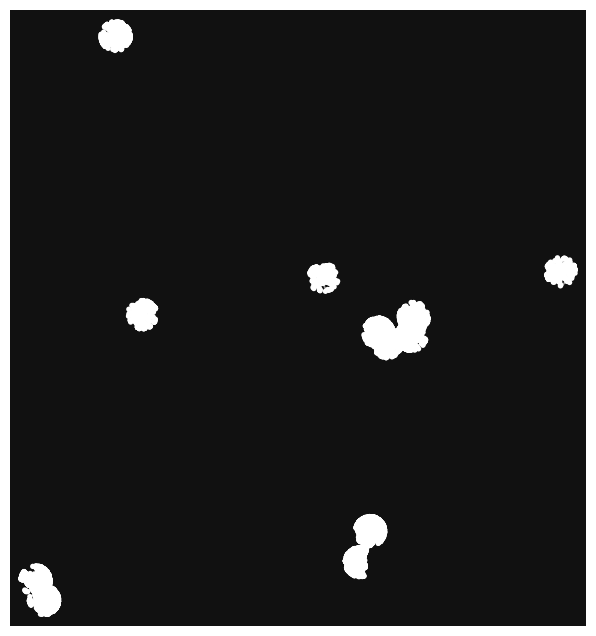

In [ ]:
# ==========================================
#  VERIFY THE GRAPH
# ==========================================
fig, ax = ox.plot_graph(G, show=True, close=True)

In [ ]:
# ==============================================================================
# FINAL STATION ENRICHMENT WITH TIPLOC CODE & TOPOLOGICAL VALIDATION REPORT
# ==============================================================================
import geopandas as gpd
import osmnx as ox
import os
import json

# Define Paths
BASE_DIR = PROJECT_ROOT
points_gpkg_path = os.path.join(BASE_DIR, '01_raw_data/Stations_and_2000m_Buffer/All_Stations.gpkg')
output_nodes_path = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')
log_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Load Station Data (Using the source containing TIPLOC)
print("Loading station points and validating TIPLOC schema...")
gdf_points = gpd.read_file(points_gpkg_path, layer='All_Stations')

# Validate TIPLOC column presence (Handle potential naming variations)
potential_tiploc_cols = [c for c in gdf_points.columns if 'tiploc' in c.lower()]
if not potential_tiploc_cols:
    raise KeyError("TIPLOC column not found in All_Stations file.")

# Rename to standard TIPLOC if necessary
if 'TIPLOC' not in gdf_points.columns:
    gdf_points = gdf_points.rename(columns={potential_tiploc_cols[0]: 'TIPLOC'})

# Project to EPSG:27700
stations_final = gdf_points.to_crs("EPSG:27700")

print(f"Snapping {len(stations_final)} stations to fully-connected graph nodes...")
new_nearest_nodes = []
for idx, row in stations_final.iterrows():
    # 'G' must be your pre-loaded road network graph
    nearest = ox.nearest_nodes(G, X=row.geometry.x, Y=row.geometry.y)
    new_nearest_nodes.append(nearest)
stations_final['nearest_node'] = new_nearest_nodes

# Save Final Lookup Table
stations_final[['TIPLOC', 'CommonName', 'nearest_node', 'geometry']].to_file(output_nodes_path, driver='GPKG')

# Validation report
duplicates = stations_final['nearest_node'].duplicated().any()
print("\n" + "="*60)
print("TOPOLOGICAL VALIDATION REPORT")
print("="*60)
print(f"Total Stations Processed: {len(stations_final)}")
print(f"Duplicate Junctions Detected: {duplicates}")

if duplicates:
    print("\n[METHODOLOGICAL NOTE: SHARED ACCESS JUNCTIONS]")
    print("The snapping process identified shared network nodes for multiple stations.")
    # Log duplicate junctions to attrition log
    dup_count = stations_final['nearest_node'].duplicated().sum()
else:
    print("Topological Integrity: All stations mapped to unique network junctions.")
    dup_count = 0

print("="*60)
print("Station Node Lookup Table finalised and saved.")

# Update Attrition Log
if os.path.exists(log_path):
    with open(log_path, 'r') as f:
        attrition_log = json.load(f)
else:
    attrition_log = {}

attrition_log["Part_3_Station_Network_Enrichment"] = {
    "01_Total_Stations": len(stations_final),
    "02_Unique_Network_Nodes": int(len(stations_final) - dup_count),
    "03_Shared_Access_Nodes": int(dup_count),
    "Note": "Stations snapped to nearest graph node using OSGB (EPSG:27700). Shared nodes indicate multi-station access points or transport hubs."
}

with open(log_path, 'w') as f:
    json.dump(attrition_log, f, indent=4)

Loading station points and validating TIPLOC schema...
Snapping 12 stations to fully-connected graph nodes...

TOPOLOGICAL VALIDATION REPORT
Total Stations Processed: 12
Duplicate Junctions Detected: False
Topological Integrity: All stations mapped to unique network junctions.
Station Node Lookup Table finalised and saved.


In [ ]:
# ==========================================
# POST-CHECK: QUERY THE STATION NODES GEOPACKAGE(ALL COLUMNS)
# ==========================================
import osmnx as ox
import pandas as pd
import geopandas as gpd

# Force pandas to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Define the path
output_nodes_path = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')

# Load and print the full table
gdf_verify = gpd.read_file(output_nodes_path)

print("--- FULL STATION NODES ATTRIBUTE TABLE ---")
print(gdf_verify)

--- FULL STATION NODES ATTRIBUTE TABLE ---
     TIPLOC                             CommonName  nearest_node               geometry
0   BRNSTPS                Barnstaple Rail Station   12847557694  POINT (255540 132549)
1   CREDITN                  Crediton Rail Station     322082642   POINT (283998 99489)
2     DIGBY            Digby & Sowton Rail Station    1201597565   POINT (296066 91552)
3   EXETRST          Exeter St Thomas Rail Station    2032757014   POINT (291471 91974)
4   HONITNS                   Honiton Rail Station    1150849392  POINT (316460 100340)
5     MSBTN              Marsh Barton Rail Station   10766731245   POINT (292651 90558)
6   OKHMPTN                Okehampton Rail Station    5491751887   POINT (259209 94440)
7    PINHOE                    Pinhoe Rail Station     368238805   POINT (296338 94169)
8   DEVNPRT                 Devonport Rail Station     501612038   POINT (245757 55430)
9   STBDXVR  St Budeaux Victoria Road Rail Station    8404678281   POINT (244

In [ ]:
# ==============================================================================
# PRE-ROUTING CHECK - RESIDENTIAL
# ==============================================================================
import os
import geopandas as gpd
import osmnx as ox
import pandas as pd

# Define Paths
BASE_DIR = PROJECT_ROOT
paths = {
    "Graph": os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.graphml'),
    "Stations": os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg'),
    "Residential": os.path.join(BASE_DIR, '02_processed_data/03_model_ready/devon_master_residential.parquet')
}

print("--- STARTING AUDIT ---")

# Check Existence
for name, path in paths.items():
    if os.path.exists(path):
        print(f"PASS: {name} found at {path}")
    else:
        print(f"FAIL: {name} NOT FOUND at {path}")

# Load Graph (This is usually the step that takes the longest)
print("Loading Graph (this may take 1-2 minutes)...")
try:
    G = ox.load_graphml(paths["Graph"])
    print(f"PASS: Graph loaded successfully ({len(G.nodes)} nodes).")
except Exception as e:
    print(f"FAIL: Could not load Graph. Error: {e}")

# Validate Station Lookup
print("Checking Stations table...")
try:
    stations = gpd.read_file(paths["Stations"])
    if 'nearest_node' in stations.columns:
        print(f"PASS: Stations table has 'nearest_node'. Count: {len(stations)}")
    else:
        print("FAIL: Stations table missing 'nearest_node' column.")
except Exception as e:
    print(f"FAIL: Could not read Stations file. Error: {e}")

# Validate Residential Data
print("Checking Residential data...")
try:
    res = gpd.read_parquet(paths["Residential"])
    print(f"PASS: Residential data loaded. Properties count: {len(res)}")
    print(f"CRS detected: {res.crs}")
    if res.crs == "EPSG:27700":
        print("PASS: CRS is correct (EPSG:27700).")
    else:
        print(f"WARNING: CRS is {res.crs} (Needs reprojection).")
except Exception as e:
    print(f"FAIL: Could not read Residential file. Error: {e}")

print("--- AUDIT COMPLETE ---")

--- STARTING AUDIT ---
PASS: Graph found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/devon_walk_network.graphml
PASS: Stations found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/station_nodes.gpkg
PASS: Residential found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/03_model_ready/devon_master_residential.parquet
Loading Graph (this may take 1-2 minutes)...
PASS: Graph loaded successfully (37221 nodes).
Checking Stations table...
PASS: Stations table has 'nearest_node'. Count: 12
Checking Residential data...
PASS: Residential data loaded. Properties count: 43413
CRS detected: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "OSGB36 / British National Grid", "base_crs": {"name": "OSGB36", "datum": {"type": "GeodeticReferenceFrame", "name": "Ordnance Survey of Great Britain 1936", "ellipsoid": {"name": "Airy 1830", "semi_major_axis": 6377563.396, 

In [ ]:
# ==============================================================================
# RESIDENTIAL NETWORK ANALYSIS
# ==============================================================================

import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import os
import logging
from tqdm import tqdm
import json
from datetime import datetime

# Setup Logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(message)s')
logger = logging.getLogger(__name__)

# Define Paths
BASE_DIR = PROJECT_ROOT
graph_path = os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.graphml')
station_nodes_path = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')
residential_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/devon_master_residential.parquet')
output_path = os.path.join(BASE_DIR, '02_processed_data/04_network/residential_distances.parquet')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Ensure directory exists for logs
os.makedirs(os.path.dirname(attrition_path), exist_ok=True)

# Load Data
logger.info("Loading Network, Stations, and Residential Data...")
G = ox.load_graphml(graph_path)
stations_gdf = gpd.read_file(station_nodes_path)
res_gdf = gpd.read_parquet(residential_path)

# List of valid station nodes for the routing algorithm
station_node_list = stations_gdf['nearest_node'].unique().tolist()

# Snap Properties using Centroids
logger.info("Snapping residential centroids to network...")
centroids = res_gdf.geometry.centroid
res_gdf['node_id'] = ox.nearest_nodes(G, X=centroids.x, Y=centroids.y)

logger.info("Associating station identities via spatial nearest-neighbor...")

# Create a temporary GeoDataFrame using the exact property centroids
res_gdf_geo = gpd.GeoDataFrame(res_gdf, geometry=centroids, crs="EPSG:27700")

# Perform spatial join to reliably get 'CommonName' regardless of node_id matching
res_gdf_joined = gpd.sjoin_nearest(res_gdf_geo, stations_gdf[['CommonName', 'geometry']], how='left', distance_col="temp_dist")

# Overwrite original res_gdf with enriched data, instantly dropping redundant join artifacts
res_gdf = res_gdf_joined.drop(columns=['index_right', 'temp_dist', 'geometry'], errors='ignore')

# Route
def get_nearest_station_dist(start_node):
    try:
        lengths = nx.multi_source_dijkstra_path_length(G, {start_node}, weight='length')
        distances = {node: dist for node, dist in lengths.items() if node in station_node_list}
        return min(distances.values()) if distances else None
    except:
        return None

logger.info("Computing walking distances (Dijkstra)...")
tqdm.pandas(desc="Routing Progress")
res_gdf['walk_dist_m'] = res_gdf['node_id'].progress_apply(get_nearest_station_dist)

# Distance band categorisation
logger.info("Categorizing walking distances into bands...")
res_gdf['Distance_Band'] = pd.cut(
    res_gdf['walk_dist_m'],
    bins=[0, 400, 800, 1200, 1600, float('inf')],
    labels=['0-400m', '400-800m', '800-1200m', '1200-1600m', '1600m+']
)

# Handle Attrition
failed_routing = res_gdf[res_gdf['walk_dist_m'].isna()]
if len(failed_routing) > 0:
    if os.path.exists(attrition_path):
        with open(attrition_path, 'r') as f:
            log_data = json.load(f)
    else:
        log_data = {}

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    log_data[f"Residential_Routing_Attrition_{timestamp}"] = {
        "failed_count": len(failed_routing),
        "total_count": len(res_gdf),
        "note": "Failed to compute network distance to nearest rail station"
    }
    with open(attrition_path, 'w') as f:
        json.dump(log_data, f, indent=4)
    logger.info(f"Attrition log updated at: {attrition_path}")

# Final Export
res_gdf = pd.DataFrame(res_gdf) # Ensure clean standard DataFrame format for parquet
res_gdf.to_parquet(output_path, index=False)

# Print Execution Summary
print("\n" + "="*50)
print("NETWORK ROUTING & ENRICHMENT SUMMARY")
print("="*50)
print(f"Total Properties Processed: {len(res_gdf):,}")
print(f"Successfully Routed:        {len(res_gdf) - len(failed_routing):,}")
print(f"Station Mappings Assigned:  {res_gdf['CommonName'].notna().sum():,}")
print(f"Distance Bands Created:     {res_gdf['Distance_Band'].notna().sum():,}")
print(f"Failed Routes (Attrition):  {len(failed_routing):,}")
print("-" * 50)
print(f"Output Data Saved To:       {output_path}")
print("="*50 + "\n")

logger.info("Process finished successfully.")

Routing Progress: 100%|██████████| 43413/43413 [40:11<00:00, 18.00it/s]



NETWORK ROUTING & ENRICHMENT SUMMARY
Total Properties Processed: 43,413
Successfully Routed:        42,086
Station Mappings Assigned:  43,413
Distance Bands Created:     42,075
Failed Routes (Attrition):  1,327
--------------------------------------------------
Output Data Saved To:       /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/residential_distances.parquet



In [ ]:
# ==============================================================================
# POST-ROUTING CHECK: RESIDENTIAL NETWORK ANALYSIS
# ==============================================================================

import pandas as pd
import os

BASE_DIR = PROJECT_ROOT
residential_distances_path = os.path.join(BASE_DIR, '02_processed_data/04_network/residential_distances.parquet')

df = pd.read_parquet(residential_distances_path)

print("==================================================")
print("TRUE WALKING DISTANCE SUMMARY STATISTICS (metres)")
print("==================================================")
# We drop the NA values (the 743 failed routes) just for this statistical view
print(df['walk_dist_m'].dropna().describe())
print("==================================================")

# Let's also look at a quick snapshot of the top 5
print("\nFirst 5 successfully routed properties:")
print(df.dropna(subset=['walk_dist_m'])[['Postcode', 'walk_dist_m']].head())

zeros = df[df['walk_dist_m'] == 0.0]
print(f"Zero distances: {len(zeros):,} ({len(zeros)/len(df)*100:.1f}%)")

print("\nWalking distance percentiles:")
print(df['walk_dist_m'].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

print("\nDistance band distribution:")
bins = [0, 200, 400, 600, 800, 1200, 1600, 2000, float('inf')]
labels = ['0-200m', '200-400m', '400-600m', '600-800m', '800m-1.2km', '1.2-1.6km', '1.6-2km', '>2km']
df['dist_band'] = pd.cut(df['walk_dist_m'], bins=bins, labels=labels)
print(df['dist_band'].value_counts().sort_index())

TRUE WALKING DISTANCE SUMMARY STATISTICS (metres)
count    42086.000000
mean      1799.859025
std       1270.635531
min          0.000000
25%       1052.087822
50%       1627.805283
75%       2140.520813
max       9656.774309
Name: walk_dist_m, dtype: float64

First 5 successfully routed properties:
   Postcode  walk_dist_m
0   TQ2 7RS  2592.669248
1  EX17 2BP  1479.005765
2   EX4 1SR  1729.846708
3   PL1 5BX  2060.761541
4  EX31 3RH  2582.746353
Zero distances: 11 (0.0%)

Walking distance percentiles:
0.10     678.405427
0.25    1052.087822
0.50    1627.805283
0.75    2140.520813
0.90    2726.711369
0.99    8499.685200
Name: walk_dist_m, dtype: float64

Distance band distribution:
dist_band
0-200m          176
200-400m        980
400-600m       1978
600-800m       2939
800m-1.2km     7161
1.2-1.6km      7259
1.6-2km        8466
>2km          13116
Name: count, dtype: int64


In [ ]:
# ==============================================================================
# POST-ROUTING CHECK - CHECKING THE OUTPUT PARQUET FILE (RESIDENTIAL)
# =============================================================================
import pandas as pd
import os

# Mapped Colab Path
BASE_DIR = PROJECT_ROOT
residential_distances_path = os.path.join(BASE_DIR, '02_processed_data/04_network/residential_distances.parquet')

def inspect_residential_distances():
    if not os.path.exists(residential_distances_path):
        print(f"File not found at: {residential_distances_path}")
        return

    print(f"Loading {residential_distances_path}...\n")
    df = pd.read_parquet(residential_distances_path)

    print("=" * 50)
    print("DATAFRAME INFO")
    print("=" * 50)
    df.info()

    print("\n" + "=" * 50)
    print("WALKING DISTANCE SUMMARY STATISTICS (meters)")
    print("=" * 50)
    # Display statistics for the newly calculated route distance
    print(df['walk_dist_m'].describe())

    print("\n" + "=" * 50)
    print("FIRST 5 ROWS")
    print("=" * 50)
    # Display a snapshot of the dataframe
    print(df.head())

inspect_residential_distances()

Loading /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/residential_distances.parquet...

DATAFRAME INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43413 entries, 0 to 43412
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    43413 non-null  object        
 1   Price             43413 non-null  int64         
 2   Price_Normalised  43413 non-null  float64       
 3   Log_Price         43413 non-null  float64       
 4   Date_of_Transfer  43413 non-null  datetime64[ns]
 5   Postcode          43413 non-null  object        
 6   Property_Type     43413 non-null  object        
 7   Is_New_Build      43413 non-null  int64         
 8   PAON              43413 non-null  object        
 9   SAON              43413 non-null  object        
 10  Street            43413 non-null  object        
 11  Total_Floor_Area  32784 non-null  float64       
 

In [ ]:
# ==============================================================================
# NETWORK RAIL JSON RAIL PARSING PRE-CHECK (RESIDENTIAL)
# ==============================================================================
import json
import os
from collections import defaultdict

BASE_DIR = PROJECT_ROOT
raw_schedule_path = os.path.join(BASE_DIR, '01_raw_data/transport/network_rail_schedule.json')

# A dictionary to hold all discovered TIPLOCs for each station
discovery_map = defaultdict(set)

# Your known station list for filtering
stations_of_interest = [
    "Barnstaple", "Crediton", "Digby", "Exeter", "Honiton",
    "Marsh Barton", "Okehampton", "Pinhoe", "Devonport",
    "St Budeaux", "Paignton", "Torre"
]

with open(raw_schedule_path, 'r') as file:
    for line in file:
        try:
            record = json.loads(line)

            def find_tiplocs(obj):
                if isinstance(obj, dict):
                    # Check if this record is a location/tiploc record
                    if 'tiploc_code' in obj and ('description' in obj or 'tps_description' in obj):
                        desc = str(obj.get('description') or obj.get('tps_description', '')).upper()
                        tiploc = obj.get('tiploc_code')

                        # Check if any of our stations are in the description
                        for station in stations_of_interest:
                            if station.upper() in desc:
                                discovery_map[station].add(tiploc)

                    for v in obj.values(): find_tiplocs(v)
                elif isinstance(obj, list):
                    for item in obj: find_tiplocs(item)

            find_tiplocs(record)
        except: continue

print("DISCOVERED TIPLOC CODES PER STATION:")
for station, tiplocs in discovery_map.items():
    print(f" - {station:<15}: {', '.join(tiplocs)}")

DISCOVERED TIPLOC CODES PER STATION:
 - Barnstaple     : BRNSTSA, BRNSTPS, BRNSTPL, BRNSSGS
 - Crediton       : CRED11, CREDSDG, CREDITN
 - Devonport      : DEVNPRT, DEVNEXS, DEVNARB
 - Digby          : DIGBY
 - Exeter         : EXET675, EXETDPT, EXETERC, EXETPBS, EXET681, EXETAIR, EXETOY, EXETGBR, EXETRRY, EXETE35, EXET664, EXETRGB, EXET730, EXETTMD, EXETMBS, EXETRFH, EXET677, EXETRCB, EXETRNY, EXET335, EXETRSD, EXETCCE, EXET679, EXETRST, EXETRFP
 - Honiton        : HONI808, HONITNS, HONIT3T, HONI803, HONICE, HONITON
 - Marsh Barton   : MSBTN
 - Okehampton     : OKHMPWS, OKHMPFS, OKHMPIC, OKHMPMP, OKHMGOP, OKHMPTN
 - Paignton       : PAIG3, PAIGNTN, PAIGXGF, PAIGDVL, PAIGTQP
 - Pinhoe         : PINHOE, PINHEJ1
 - St Budeaux     : STBDXJN, STBDXFR, STBDXVR
 - Torre          : TORRE


In [ ]:
# ==============================================================================
# NETWORK RAIL: STATION STOP-EVENT INTENSITY INDEX (SEII) - SERVICE FREQUENCY (RESIDENTIAL)
# ==============================================================================

import json
import os
from collections import defaultdict
from datetime import datetime

BASE_DIR = PROJECT_ROOT
raw_schedule_path = os.path.join(BASE_DIR, '01_raw_data/transport/network_rail_schedule.json')
output_frequency_path = os.path.join(BASE_DIR, '02_processed_data/04_network/rail_service_frequency.json')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Master Mapping
master_station_map = {
    'Barnstaple': ['BRNSSGS', 'BRNSTPS', 'BRNSTSA', 'BRNSTPL'],
    'Crediton': ['CREDITN', 'CREDSDG', 'CRED11'],
    'Devonport': ['DEVNPRT', 'DEVNEXS', 'DEVNARB'],
    'Digby & Sowton': ['DIGBY'],
    'Exeter St Thomas': ['EXETRST'],
    'Honiton': ['HONITNS', 'HONIT3T', 'HONITON', 'HONICE', 'HONI803', 'HONI808'],
    'Marsh Barton': ['MSBTN'],
    'Okehampton': ['OKHMPTN', 'OKHMGOP', 'OKHMPMP', 'OKHMPWS', 'OKHMPFS', 'OKHMPIC'],
    'Paignton': ['PAIGNTN', 'PAIG3', 'PAIGXGF', 'PAIGTQP', 'PAIGDVL'],
    'Pinhoe': ['PINHOE', 'PINHEJ1'],
    'St Budeaux Victoria Road': ['STBDXVR', 'STBDXFR', 'STBDXJN'],
    'Torre': ['TORRE']
}

tiploc_to_station = {tiploc: station for station, tiplocs in master_station_map.items() for tiploc in tiplocs}

def extract_stp(obj):
    """Recursively find STP indicator."""
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in ("stp_indicator", "CIF_stp_indicator"): return v
            res = extract_stp(v)
            if res is not None: return res
    elif isinstance(obj, list):
        for i in obj:
            res = extract_stp(i)
            if res is not None: return res
    return None

service_counts = defaultdict(int)
cancelled_count = 0
total_records = 0

with open(raw_schedule_path, 'r') as file:
    for line in file:
        total_records += 1
        try:
            record = json.loads(line)

            # Skip planned cancellations
            if extract_stp(record) == 'C':
                cancelled_count += 1
                continue

            # De-duplication set for this specific schedule record
            # We track (tiploc, arrival, departure) to ensure uniqueness
            seen_in_record = set()

            def extract(obj):
                if isinstance(obj, dict):
                    tiploc = obj.get('tiploc_code')
                    if tiploc in tiploc_to_station:
                        arr = obj.get('arrival')
                        dep = obj.get('departure')

                        # Use (tiploc, arrival, departure) as a unique fingerprint
                        fingerprint = (tiploc, arr, dep)

                        if fingerprint not in seen_in_record and (arr or dep):
                            station = tiploc_to_station[tiploc]
                            service_counts[station] += 1
                            seen_in_record.add(fingerprint)
                    for v in obj.values(): extract(v)
                elif isinstance(obj, list):
                    for item in obj: extract(item)

            extract(record)
        except: continue

# Save Logs and Frequencies
os.makedirs(os.path.dirname(attrition_path), exist_ok=True)
log_data = {}
if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f: log_data = json.load(f)

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
log_data[f"Final_SEII_Parse_{timestamp}"] = {
    "total_records_scanned": total_records,
    "cancelled_services_removed": cancelled_count,
    "note": "Station Stop-Event Intensity Index (SEII). Fingerprinted via (tiploc, arr, dep)."
}

with open(attrition_path, 'w') as f: json.dump(log_data, f, indent=4)
with open(output_frequency_path, 'w') as f: json.dump(dict(service_counts), f, indent=4)

print("CALCULATED SERVICE INTENSITY INDEX (SEII)")
print("-" * 50)
for station in sorted(master_station_map.keys()):
    print(f"{station:<30}: {service_counts[station]} stop-events")

CALCULATED SERVICE INTENSITY INDEX (SEII)
--------------------------------------------------
Barnstaple                    : 921 stop-events
Crediton                      : 661 stop-events
Devonport                     : 207 stop-events
Digby & Sowton                : 512 stop-events
Exeter St Thomas              : 354 stop-events
Honiton                       : 781 stop-events
Marsh Barton                  : 300 stop-events
Okehampton                    : 1186 stop-events
Paignton                      : 863 stop-events
Pinhoe                        : 721 stop-events
St Budeaux Victoria Road      : 211 stop-events
Torre                         : 521 stop-events


In [ ]:
# ==============================================================================
# POST-CHECK: INSPECTING PARSED NETWORK RAIL SERVICE FREQUENCY FILE (RESIDENTIAL)
# ==============================================================================
import json
import os

output_frequency_path = os.path.join(PROJECT_ROOT, '02_processed_data/04_network/rail_service_frequency.json')

with open(output_frequency_path, 'r') as f:
    data = json.load(f)

print(f"{'TIPLOC':<10} | {'Daily Stops':<12}")
print("-" * 25)
for tiploc, count in data.items():
    print(f"{tiploc:<10} | {count:<12}")

TIPLOC     | Daily Stops 
-------------------------
Okehampton | 1186        
Paignton   | 863         
Crediton   | 661         
Barnstaple | 921         
Devonport  | 207         
St Budeaux Victoria Road | 211         
Digby & Sowton | 512         
Honiton    | 781         
Pinhoe     | 721         
Torre      | 521         
Marsh Barton | 300         
Exeter St Thomas | 354         


In [ ]:
# ==============================================================================
# ENRICHMENT & MODEL-READY EXPORT (RESIDENTIAL)
# ==============================================================================

import pandas as pd
import json
import os
from datetime import datetime

BASE_DIR = PROJECT_ROOT
res_input_path = os.path.join(BASE_DIR, '02_processed_data/04_network/residential_distances.parquet')
seii_data_path = os.path.join(BASE_DIR, '02_processed_data/04_network/rail_service_frequency.json')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Load Data
df = pd.read_parquet(res_input_path)
with open(seii_data_path, 'r') as f:
    seii_map = json.load(f)

# Epoch Logic
def assign_epoch(station, sale_date):
    if pd.isna(sale_date) or pd.isna(station): return 'UNKNOWN'
    station_clean = str(station).replace(" Rail Station", "").strip()

    okehampton_group = ['Okehampton', 'Crediton', 'Barnstaple', 'Honiton']
    marsh_barton_group = [
        'Marsh Barton', 'Exeter St Thomas', 'Digby & Sowton',
        'Pinhoe', 'Devonport', 'St Budeaux Victoria Road',
        'Torre', 'Paignton'
    ]

    if station_clean in okehampton_group:
        if sale_date < pd.Timestamp('2021-03-01'): return 'Baseline'
        if sale_date < pd.Timestamp('2021-04-01'): return 'Announcement'
        if sale_date < pd.Timestamp('2021-11-20'): return 'Construction'
        return 'Operational'
    elif station_clean in marsh_barton_group:
        if sale_date < pd.Timestamp('2021-01-01'): return 'Baseline'
        if sale_date < pd.Timestamp('2021-04-01'): return 'Announcement'
        if sale_date < pd.Timestamp('2023-07-04'): return 'Construction'
        return 'Operational'
    return 'UNKNOWN_STATION'

df['Date_of_Transfer'] = pd.to_datetime(df['Date_of_Transfer'])
df['Epoch'] = df.apply(lambda row: assign_epoch(row['CommonName'], row['Date_of_Transfer']), axis=1)

# SEII Enrichment
df['Service_Intensity_SEII'] = df['CommonName'].fillna("").str.replace(" Rail Station", "").str.strip().map(seii_map).fillna(0)

# Final Cleanup & Logging
initial_count = len(df)
df_clean = df.dropna(subset=['walk_dist_m', 'LSOA21CD', 'IMD_Decile']).copy()

if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f: log_data = json.load(f)
else:
    log_data = {}

log_data[f"Res_Model_Ready_{datetime.now().strftime('%Y%m%d_%H%M')}"] = {
    "Initial_Count": initial_count,
    "Dropped_Count": initial_count - len(df_clean),
    "Final_Count": len(df_clean)
}
with open(attrition_path, 'w') as f: json.dump(log_data, f, indent=4)

# Export
df_clean.to_parquet(os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet'), index=False)
print(f"Residential Enrichment complete. Final rows: {len(df_clean):,}")

Residential Enrichment complete. Final rows: 41,888


In [ ]:
# ==============================================================================
# DATA CLEANUP (RESIDENTIAL)
# ==============================================================================

import pandas as pd
import os
import json
from datetime import datetime

BASE_DIR = PROJECT_ROOT
res_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Load the model-ready residential file
df = pd.read_parquet(res_path)
initial_count = len(df)

# Drop the (PAON/SAON columns
df = df.drop(columns=['PAON', 'SAON'])

# Remove any property with missing data in the remaining columns
df_clean = df.dropna().copy()

final_count = len(df_clean)
dropped_count = initial_count - final_count

# Update attrition log
os.makedirs(os.path.dirname(attrition_path), exist_ok=True)

if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f:
        try:
            log_data = json.load(f)
        except json.JSONDecodeError:
            log_data = {}
else:
    log_data = {}

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
log_data[f"Residential_Strict_Complete_Case_Analysis_{timestamp}"] = {
    "Initial_Count": initial_count,
    "Dropped_Count": dropped_count,
    "Final_Count": final_count,
    "Note": "Dropped PAON/SAON columns. Applied dataset-wide dropna() on remaining attributes to ensure regression models are built only on complete observations."
}

with open(attrition_path, 'w') as f:
    json.dump(log_data, f, indent=4)

# Save the clean dataset back to Parquet
df_clean.to_parquet(res_path, index=False)

print("==================================================")
print("STRICT COMPLETE CASE ANALYSIS APPLIED")
print("==================================================")
print(f"Original Rows:  {initial_count:,}")
print(f"Rows Dropped:   {dropped_count:,}")
print(f"Final Rows:     {final_count:,}")
print("-" * 50)
print(f"Total Missing Values Remaining: {df_clean.isna().sum().sum()}")
print("-" * 50)
print(f"✅ Attrition successfully logged to: \n{attrition_path}")
print("==================================================")
print("Data is now 100% complete, PAON/SAON stripped, and ready for regression.")

Null counts before dropna:
Series([], dtype: int64)
Total rows with any null: 0
STRICT COMPLETE CASE ANALYSIS APPLIED
Original Rows:  31,883
Rows Dropped:   0
Final Rows:     31,883
--------------------------------------------------
Total Missing Values Remaining: 0
--------------------------------------------------
✅ Attrition successfully logged to: 
/content/drive/MyDrive/MSc_Dissertation_Project/05_logs/script_logs/attrition_log.json
Data is now 100% complete, PAON/SAON stripped, and ready for regression.


In [ ]:
# ==============================================================================
# POST-CHECK - CHECKING THE OUTPUT PARQUET FILE (RESIDENTIAL)
# =============================================================================
import pandas as pd
import os

BASE_DIR = PROJECT_ROOT
res_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')

def inspect_residential_data():
    if not os.path.exists(res_path):
        print(f"File not found at: {res_path}")
        return

    print(f"Loading {res_path}...\n")
    df = pd.read_parquet(res_path)

    # Adjust display options to ensure all columns are visible
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)

    print("==================================================")
    print("RESIDENTIAL DATAFRAME INFO")
    print("==================================================")
    df.info()

    print("\n==================================================")
    print("WALKING DISTANCE SUMMARY STATISTICS (meters)")
    print("==================================================")
    print(df['walk_dist_m'].describe())

    print("\n==================================================")
    print("DATA INTEGRITY & DISTRIBUTIONS")
    print("==================================================")
    print(f"Total Rows: {len(df):,}")

    print("\n--- Distribution of Epochs ---")
    print(df['Epoch'].value_counts())

    print("\n--- Distribution of Distance Bands ---")
    print(df['Distance_Band'].value_counts())

    print("\n--- Missing values per column ---")
    print(df.isna().sum())

    print("\n==================================================")
    print("FIRST 5 ROWS")
    print("==================================================")
    print(df.head(5))

inspect_residential_data()

Loading /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/03_model_ready/regression_ready_residential.parquet...

RESIDENTIAL DATAFRAME INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31883 entries, 0 to 31882
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Transaction_ID          31883 non-null  object        
 1   Price                   31883 non-null  int64         
 2   Price_Normalised        31883 non-null  float64       
 3   Log_Price               31883 non-null  float64       
 4   Date_of_Transfer        31883 non-null  datetime64[ns]
 5   Postcode                31883 non-null  object        
 6   Property_Type           31883 non-null  object        
 7   Is_New_Build            31883 non-null  int64         
 8   Street                  31883 non-null  object        
 9   Total_Floor_Area        31883 non-null  float64       
 10  Log_Floor

In [ ]:
# ==============================================================================
# PRE-ROUTING CHECK - COMMERCIAL
# ==============================================================================
import os
import geopandas as gpd
import osmnx as ox
import pandas as pd

# Define Paths
BASE_DIR = PROJECT_ROOT
paths = {
    "Graph": os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.graphml'),
    "Stations": os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg'),
    "Commercial": os.path.join(BASE_DIR, '02_processed_data/03_model_ready/devon_master_commercial.parquet')
}

print("--- STARTING COMMERCIAL AUDIT ---")

# Check Existence
for name, path in paths.items():
    if os.path.exists(path):
        print(f"PASS: {name} found at {path}")
    else:
        print(f"FAIL: {name} NOT FOUND at {path}")

# Load Graph
print("Loading Graph...")
try:
    G = ox.load_graphml(paths["Graph"])
    print(f"PASS: Graph loaded successfully ({len(G.nodes)} nodes).")
except Exception as e:
    print(f"FAIL: Could not load Graph. Error: {e}")

# Validate Station Lookup
print("Checking Stations table...")
try:
    stations = gpd.read_file(paths["Stations"])
    if 'nearest_node' in stations.columns:
        print(f"PASS: Stations table has 'nearest_node'. Count: {len(stations)}")
    else:
        print("FAIL: Stations table missing 'nearest_node' column.")
except Exception as e:
    print(f"FAIL: Could not read Stations file. Error: {e}")

# Validate Commercial Data
print("Checking Commercial VOA data...")
try:
    # Commercial data is usually Point geometry (VOA business locations)
    com = gpd.read_parquet(paths["Commercial"])
    print(f"PASS: Commercial data loaded. Business points count: {len(com)}")
    print(f"CRS detected: {com.crs}")

    # Check for essential commercial columns
    required_cols = ['Rateable_Value', 'Property_Sector', 'Total_Floor_Area']
    missing = [c for c in required_cols if c not in com.columns]
    if not missing:
        print(f"PASS: All required commercial columns found: {required_cols}")
    else:
        print(f"FAIL: Missing columns: {missing}")

    if com.crs == "EPSG:27700":
        print("PASS: CRS is correct (EPSG:27700).")
    else:
        print(f"WARNING: CRS is {com.crs} (Needs reprojection).")
except Exception as e:
    print(f"FAIL: Could not read Commercial file. Error: {e}")

print("--- COMMERCIAL AUDIT COMPLETE ---")

--- STARTING COMMERCIAL AUDIT ---
PASS: Graph found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/devon_walk_network.graphml
PASS: Stations found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/station_nodes.gpkg
PASS: Commercial found at /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/03_model_ready/devon_master_commercial.parquet
Loading Graph...
PASS: Graph loaded successfully (37221 nodes).
Checking Stations table...
PASS: Stations table has 'nearest_node'. Count: 12
Checking Commercial VOA data...
PASS: Commercial data loaded. Business points count: 28361
CRS detected: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "OSGB36 / British National Grid", "base_crs": {"name": "OSGB36", "datum": {"type": "GeodeticReferenceFrame", "name": "Ordnance Survey of Great Britain 1936", "ellipsoid": {"name": "Airy 1830", "semi_major_axis": 6377563.396, "inverse_fla

In [ ]:
# ==============================================================================
# COMMERCIAL NETWORK ANALYSIS
# ==============================================================================

import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import os
import logging
from tqdm import tqdm
import json
from datetime import datetime

# Setup Logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(message)s')
logger = logging.getLogger(__name__)

# Define Paths
BASE_DIR = PROJECT_ROOT
paths = {
    "Graph": os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.graphml'),
    "Stations": os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg'),
    "Commercial": os.path.join(BASE_DIR, '02_processed_data/03_model_ready/devon_master_commercial.parquet')
}
output_path = os.path.join(BASE_DIR, '02_processed_data/04_network/commercial_distances.parquet')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Ensure directory exists for logs
os.makedirs(os.path.dirname(attrition_path), exist_ok=True)

# Load Data
logger.info("Loading Network, Stations, and Commercial Data...")
G = ox.load_graphml(paths["Graph"])
stations_gdf = gpd.read_file(paths["Stations"])
com_gdf = gpd.read_parquet(paths["Commercial"])

# List of valid station nodes for the routing algorithm
station_node_list = stations_gdf['nearest_node'].unique().tolist()

# Snap Commercial Points to network
logger.info("Snapping commercial points to network...")
# Using centroids guarantees it works whether the data is Point or Polygon
centroids = com_gdf.geometry.centroid
com_gdf['node_id'] = ox.nearest_nodes(G, X=centroids.x, Y=centroids.y)

# ------------------------------------------------------------------------------
# INTEGRATED SPATIAL ENRICHMENT & CLEANUP
# ------------------------------------------------------------------------------
logger.info("Associating station identities via spatial nearest-neighbor...")

# Create a temporary GeoDataFrame to perform the robust spatial join
com_gdf_geo = gpd.GeoDataFrame(com_gdf, geometry=centroids, crs="EPSG:27700")

# Perform spatial join to reliably get 'CommonName'
com_gdf_joined = gpd.sjoin_nearest(com_gdf_geo, stations_gdf[['CommonName', 'geometry']], how='left', distance_col="temp_dist")

# Overwrite original com_gdf, dropping redundant join artifacts immediately
com_gdf = com_gdf_joined.drop(columns=['index_right', 'temp_dist', 'geometry'], errors='ignore')

# ------------------------------------------------------------------------------
# ROUTING LOGIC
# ------------------------------------------------------------------------------
def get_nearest_station_dist(start_node):
    try:
        lengths = nx.multi_source_dijkstra_path_length(G, {start_node}, weight='length')
        distances = {node: dist for node, dist in lengths.items() if node in station_node_list}
        return min(distances.values()) if distances else None
    except:
        return None

logger.info("Computing walking distances (Dijkstra)...")
tqdm.pandas(desc="Routing Progress")
com_gdf['walk_dist_m'] = com_gdf['node_id'].progress_apply(get_nearest_station_dist)

# ------------------------------------------------------------------------------
# DISTANCE BAND CATEGORIZATION
# ------------------------------------------------------------------------------
logger.info("Categorizing walking distances into bands...")
com_gdf['Distance_Band'] = pd.cut(
    com_gdf['walk_dist_m'],
    bins=[0, 400, 800, 1200, 1600, float('inf')],
    labels=['0-400m', '400-800m', '800-1200m', '1200-1600m', '1600m+']
)

# Handle Attrition
failed_routing = com_gdf[com_gdf['walk_dist_m'].isna()]
if len(failed_routing) > 0:
    if os.path.exists(attrition_path):
        with open(attrition_path, 'r') as f:
            log_data = json.load(f)
    else:
        log_data = {}

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    log_data[f"Commercial_Routing_Attrition_{timestamp}"] = {
        "failed_count": len(failed_routing),
        "total_count": len(com_gdf),
        "note": "Commercial to station routing attrition"
    }

    with open(attrition_path, 'w') as f:
        json.dump(log_data, f, indent=4)
    logger.info(f"Attrition log updated at: {attrition_path}")

# Final Export
com_gdf = pd.DataFrame(com_gdf)
com_gdf.to_parquet(output_path, index=False)

# Print Execution Summary
print("\n" + "="*50)
print("COMMERCIAL ROUTING & ENRICHMENT SUMMARY")
print("="*50)
print(f"Total Business Points Processed: {len(com_gdf):,}")
print(f"Successfully Routed:             {len(com_gdf) - len(failed_routing):,}")
print(f"Station Mappings Assigned:       {com_gdf['CommonName'].notna().sum():,}")
print(f"Distance Bands Created:          {com_gdf['Distance_Band'].notna().sum():,}")
print(f"Failed Routes (Attrition):       {len(failed_routing):,}")
print("-" * 50)
print(f"Output Data Saved To:            {output_path}")
print("="*50 + "\n")

logger.info("Commercial process finished successfully.")

Routing Progress: 100%|██████████| 28361/28361 [29:17<00:00, 16.14it/s]



COMMERCIAL ROUTING & ENRICHMENT SUMMARY
Total Business Points Processed: 28,361
Successfully Routed:             26,836
Station Mappings Assigned:       28,361
Distance Bands Created:          26,832
Failed Routes (Attrition):       1,525
--------------------------------------------------
Output Data Saved To:            /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/commercial_distances.parquet



In [ ]:
# ==============================================================================
# POST-ROUTING CHECK: COMMERCIAL NETWORK ANALYSIS
# ==============================================================================

import pandas as pd
import os

BASE_DIR = PROJECT_ROOT
# Note: Ensure you have run your Commercial routing script to create this parquet file
commercial_distances_path = os.path.join(BASE_DIR, '02_processed_data/04_network/commercial_distances.parquet')

df = pd.read_parquet(commercial_distances_path)

print("==================================================")
print("COMMERCIAL TRUE WALKING DISTANCE SUMMARY (meters)")
print("==================================================")
# Stats for successfully routed commercial points
print(df['walk_dist_m'].dropna().describe())
print("==================================================")

# Snapshot of the first 5 successfully routed businesses
print("\nFirst 5 successfully routed business locations:")
print(df.dropna(subset=['walk_dist_m'])[['Property_Sector', 'walk_dist_m']].head())

# Check for potential snapping issues (0m)
zeros = df[df['walk_dist_m'] == 0.0]
print(f"\nZero distances (snapped to node): {len(zeros):,} ({len(zeros)/len(df)*100:.1f}%)")

print("\nWalking distance percentiles (Commercial):")
print(df['walk_dist_m'].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

print("\nDistance band distribution (Commercial):")
# Using the same bins as your thesis plan to ensure comparability
bins = [0, 400, 800, 1200, 1600, float('inf')]
labels = ['0-400m', '400-800m', '800-1200m', '1200-1600m', '>1600m']
df['dist_band'] = pd.cut(df['walk_dist_m'], bins=bins, labels=labels)
print(df['dist_band'].value_counts().sort_index())

COMMERCIAL TRUE WALKING DISTANCE SUMMARY (meters)
count    26836.000000
mean      1643.607738
std       1313.773804
min          0.000000
25%        912.626585
50%       1354.353579
75%       1939.476346
max      10192.730351
Name: walk_dist_m, dtype: float64

First 5 successfully routed business locations:
                   Property_Sector  walk_dist_m
244        SUPERSTORE AND PREMISES  1765.709106
245  HAIRDRESSING SALON & PREMISES   386.248398
246              SHOP AND PREMISES   386.248398
247              SHOP AND PREMISES   386.248398
248              SHOP AND PREMISES   386.248398

Zero distances (snapped to node): 4 (0.0%)

Walking distance percentiles (Commercial):
0.10     555.054762
0.25     912.626585
0.50    1354.353579
0.75    1939.476346
0.90    2540.835124
0.99    6382.185513
Name: walk_dist_m, dtype: float64

Distance band distribution (Commercial):
dist_band
0-400m        1623
400-800m      3639
800-1200m     5639
1200-1600m    6128
>1600m        9803
Name: count, d

In [ ]:
# ==============================================================================
# POST-ROUTING CHECK - CHECKING DISTRIBUTION (COMMERCIAL)
# ==============================================================================
import pandas as pd
import os

BASE_DIR = PROJECT_ROOT
df = pd.read_parquet(os.path.join(BASE_DIR, '02_processed_data/04_network/commercial_distances.parquet'))

zeros = df[df['walk_dist_m'] == 0.0]
print(f"Zero distances: {len(zeros):,} ({len(zeros)/len(df)*100:.1f}%)")

print("\nWalking distance percentiles:")
print(df['walk_dist_m'].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

print("\nDistance band distribution:")
bins = [0, 200, 400, 600, 800, 1200, 1600, 2000, float('inf')]
labels = ['0-200m', '200-400m', '400-600m', '600-800m', '800m-1.2km', '1.2-1.6km', '1.6-2km', '>2km']
df['dist_band'] = pd.cut(df['walk_dist_m'], bins=bins, labels=labels)
print(df['dist_band'].value_counts().sort_index())

Zero distances: 4 (0.0%)

Walking distance percentiles:
0.10     555.054762
0.25     912.626585
0.50    1354.353579
0.75    1939.476346
0.90    2540.835124
0.99    6382.185513
Name: walk_dist_m, dtype: float64

Distance band distribution:
dist_band
0-200m         441
200-400m      1182
400-600m      1594
600-800m      2045
800m-1.2km    5639
1.2-1.6km     6128
1.6-2km       3562
>2km          6241
Name: count, dtype: int64


In [ ]:
# ==============================================================================
# POST-ROUTING CHECK - CHECKING THE OUTPUT PARQUET FILE (COMMERCIAL)
# ==============================================================================
import pandas as pd
import os

# Mapped Colab Path
BASE_DIR = PROJECT_ROOT
commercial_distances_path = os.path.join(BASE_DIR, '02_processed_data/04_network/commercial_distances.parquet')

def inspect_commercial_distances():
    if not os.path.exists(commercial_distances_path):
        print(f"File not found at: {commercial_distances_path}")
        return

    print(f"Loading {commercial_distances_path}...\n")
    df = pd.read_parquet(commercial_distances_path)

    print("=" * 50)
    print("COMMERCIAL DATAFRAME INFO")
    print("=" * 50)
    df.info()

    print("\n" + "=" * 50)
    print("WALKING DISTANCE SUMMARY STATISTICS (meters)")
    print("=" * 50)
    # Checking the output of the Commercial Dijkstra routing
    print(df['walk_dist_m'].describe())

    print("\n" + "=" * 50)
    print("FIRST 5 ROWS (COMMERCIAL)")
    print("=" * 50)
    # Display snapshot including commercial-specific columns
    print(df[['Rateable_Value', 'Property_Sector', 'walk_dist_m']].head())

inspect_commercial_distances()

Loading /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/commercial_distances.parquet...

COMMERCIAL DATAFRAME INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28361 entries, 0 to 28360
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Assessment_UARN     28361 non-null  object  
 1   Postcode            28361 non-null  object  
 2   Property_Sector     28361 non-null  object  
 3   Rateable_Value      28361 non-null  int64   
 4   Total_Floor_Area    28361 non-null  float64 
 5   Year                28361 non-null  int64   
 6   Log_Rateable_Value  28361 non-null  float64 
 7   Log_Floor_Area      28361 non-null  float64 
 8   east1m              28361 non-null  float64 
 9   north1m             28361 non-null  float64 
 10  LSOA21CD            28169 non-null  object  
 11  IMD_Decile          28169 non-null  float64 
 12  node_id             28361 non-null  int64 

In [ ]:
# ==============================================================================
# ENRICHMENT & MODEL-READY EXPORT (COMMERCIAL)
# ==============================================================================

import pandas as pd
import json
import os
from datetime import datetime

BASE_DIR = PROJECT_ROOT
com_input_path = os.path.join(BASE_DIR, '02_processed_data/04_network/commercial_distances.parquet')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Load Data
df = pd.read_parquet(com_input_path)
initial_rows = len(df)

# Diagnostic: properties routed but missing LSOA or IMD
routed_missing_soc = df[df['walk_dist_m'].notna() & (df['LSOA21CD'].isna() | df['IMD_Decile'].isna())].shape[0]
print(f"Successfully routed but missing LSOA or IMD: {routed_missing_soc}")

# Cleanup: Drop records where routing failed or socioeconomic data is missing
df_clean = df.dropna(subset=['walk_dist_m', 'LSOA21CD', 'IMD_Decile']).copy()
dropped_count = initial_rows - len(df_clean)

# Epoch Assignment
def assign_commercial_epoch(year):
    if year == 2017: return 'Baseline'
    elif year == 2023: return 'Anticipation'
    return 'UNKNOWN'

df_clean['Epoch'] = df_clean['Year'].apply(assign_commercial_epoch)

# Attrition Logging
if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f:
        log_data = json.load(f)
else:
    log_data = {}

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
log_data[f"Commercial_Regression_Cleanup_{timestamp}"] = {
    "Initial_Count": initial_rows,
    "Dropped_Count": dropped_count,
    "Final_Count": len(df_clean),
    "Note": "Commercial records lacking valid walk_dist_m or socio-economic data (IMD) were excluded."
}

with open(attrition_path, 'w') as f:
    json.dump(log_data, f, indent=4)

# Export
output_parquet = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')
df_clean.to_parquet(output_parquet, index=False)

print(f"Commercial Enrichment complete.")
print(f"Initial rows: {initial_rows:,}")
print(f"Final regression rows: {len(df_clean):,}")
print(f"Attrition logged in: {attrition_path}")

Successfully routed but missing LSOA or IMD: 174
Commercial Enrichment complete.
Initial rows: 28,361
Final regression rows: 26,662
Attrition logged in: /content/drive/MyDrive/MSc_Dissertation_Project/05_logs/script_logs/attrition_log.json


In [ ]:
# ==============================================================================
# DATA CLEANUP (COMMERCIAL)
# ==============================================================================
import pandas as pd
import os
import json
from datetime import datetime

BASE_DIR = PROJECT_ROOT
# Ensure you update this path if your filename differs
comm_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')
attrition_path = os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')

# Load the model-ready commercial file
df = pd.read_parquet(comm_path)
initial_count = len(df)

# Apply strict complete case analysis:
# This removes any property with missing distance bands OR missing commercial attributes (e.g., Rateable Value)
df_clean = df.dropna().copy()

final_count = len(df_clean)
dropped_count = initial_count - final_count

# Update attrition log
os.makedirs(os.path.dirname(attrition_path), exist_ok=True)

if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f:
        try:
            log_data = json.load(f)
        except json.JSONDecodeError:
            log_data = {}
else:
    log_data = {}

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
log_data[f"Commercial_Strict_Complete_Case_Analysis_{timestamp}"] = {
    "Initial_Count": initial_count,
    "Dropped_Count": dropped_count,
    "Final_Count": final_count,
    "Note": "Strict complete case analysis: Applied dataset-wide dropna() to ensure commercial regression models are built only on complete observations."
}

with open(attrition_path, 'w') as f:
    json.dump(log_data, f, indent=4)

# 5. EXPORT: Save the perfectly clean dataset back to Parquet
df_clean.to_parquet(comm_path, index=False)

print("==================================================")
print("COMMERCIAL: STRICT COMPLETE CASE ANALYSIS APPLIED")
print("==================================================")
print(f"Original Rows:  {initial_count:,}")
print(f"Rows Dropped:   {dropped_count:,}")
print(f"Final Rows:     {final_count:,}")
print("-" * 50)
print(f"Total Missing Values Remaining: {df_clean.isna().sum().sum()}")
print("-" * 50)
print(f"✅ Attrition successfully logged to: \n{attrition_path}")
print("==================================================")
print("Commercial data is now 100% complete and ready for regression modeling.")

COMMERCIAL: STRICT COMPLETE CASE ANALYSIS APPLIED
Original Rows:  26,662
Rows Dropped:   4
Final Rows:     26,658
--------------------------------------------------
Total Missing Values Remaining: 0
--------------------------------------------------
✅ Attrition successfully logged to: 
/content/drive/MyDrive/MSc_Dissertation_Project/05_logs/script_logs/attrition_log.json
Commercial data is now 100% complete and ready for regression modeling.


In [ ]:
# ==============================================================================
# POST-ROUTING CHECK - CHECKING THE OUTPUT PARQUET FILE (COMMERCIAL)
# ==============================================================================

import pandas as pd
import os

# Define the path
BASE_DIR = PROJECT_ROOT
# Pointing to your final regression-ready commercial file
parquet_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')

# Load the file
df = pd.read_parquet(parquet_path)

# Adjust display options to ensure all columns are visible
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("--- REGRESSION-READY PARQUET: COLUMN LIST ---")
print(df.columns.tolist())

print("\n--- FIRST 5 ROWS ---")
print(df.head(5))

print("\n--- DATA INTEGRITY CHECK ---")
print(f"Total Rows: {len(df):,}")
print("\nDistribution of Epochs:")
print(df['Epoch'].value_counts())
print("\nDistribution of Distance Bands:")
print(df['Distance_Band'].value_counts().sort_index())
print("\nMissing values per column:")
print(df.isnull().sum())

--- REGRESSION-READY PARQUET: COLUMN LIST ---
['Assessment_UARN', 'Postcode', 'Property_Sector', 'Rateable_Value', 'Total_Floor_Area', 'Year', 'Log_Rateable_Value', 'Log_Floor_Area', 'east1m', 'north1m', 'LSOA21CD', 'IMD_Decile', 'node_id', 'CommonName', 'walk_dist_m', 'Distance_Band', 'Epoch']

--- FIRST 5 ROWS ---
  Assessment_UARN  Postcode                Property_Sector  Rateable_Value  Total_Floor_Area  Year  Log_Rateable_Value  Log_Floor_Area    east1m   north1m   LSOA21CD  IMD_Decile     node_id            CommonName  walk_dist_m Distance_Band     Epoch
0     27581791000  EX14 2XD        SUPERSTORE AND PREMISES          805000           3560.00  2017           13.598598        8.177516  315358.0   99623.0  E01019931        10.0  5113563853  Honiton Rail Station  1765.709106        1600m+  Baseline
1     15862352000  EX14 1ES  HAIRDRESSING SALON & PREMISES            3500             23.39  2017            8.160518        3.152309  316303.0  100638.0  E01019927         4.0  16100

In [ ]:
# ==============================================================================
# QUICK FIX: ADD 1200 t0 1,6000 m BAND (REFERENCE ZONE) TO THE EXISTING BANDS
# This makes the exported isochrone bands four bands
# ==============================================================================
# Reload G from saved file — faster than re-downloading from OSM
import osmnx as ox

BASE_DIR = PROJECT_ROOT
graphml_path = f'{BASE_DIR}/02_processed_data/04_network/devon_walk_network.graphml'

G = ox.load_graphml(filepath=graphml_path)
G = ox.project_graph(G, to_crs="EPSG:27700")
print("Graph loaded from file.")
print(f"Nodes: {len(G.nodes)}, Edges: {len(G.edges)}")

Graph loaded from file.
Nodes: 37221, Edges: 91178


In [ ]:
# ==============================================================================
# QUICK FIX: Reading the station nodes into memory
# ==============================================================================
import geopandas as gpd
import os

BASE_DIR = PROJECT_ROOT
station_nodes_path = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')

stations_gdf = gpd.read_file(station_nodes_path)
station_node_list = stations_gdf['nearest_node'].unique().tolist()

print(f"station_node_list loaded: {len(station_node_list)} stations")
print(station_node_list)

station_node_list loaded: 12 stations
[12847557694, 322082642, 1201597565, 2032757014, 1150849392, 10766731245, 5491751887, 368238805, 501612038, 8404678281, 7598708337, 920685374]


In [ ]:
# ==============================================================================
# CREATE ISOCHRONE BANDS — OSMNX DIJKSTRA, DISTANCE-BASED
# isochrones built from Dijkstra routing on the BNG-projected walk graph.
# ==============================================================================

import osmnx as ox
import networkx as nx
import geopandas as gpd
import os
from shapely.geometry import Point
from shapely.ops import unary_union
import warnings
warnings.filterwarnings('ignore')

BASE_DIR      = PROJECT_ROOT
GRAPHML_PATH  = os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.graphml')
STATIONS_PATH = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')
ISO_PATH      = os.path.join(BASE_DIR, '02_processed_data/04_network/isochrone_bands.gpkg')

# ── parameters ────────────────────────────────────────────────────────────────
THRESHOLDS    = [800, 1200, 1600]   # metres — matches study design exactly
NODE_BUFFER_M = 50                  # metres; morphological closing handles rural gaps below

BAND_META = {
    800:  ('Near Zone',      0,    800),
    1200: ('Excluded Zone',  800,  1200),
    1600: ('Reference Zone', 1200, 1600),
}

# ── load graph and stations ───────────────────────────────────────────────────
print("Loading Devon walk graph from GraphML (BNG)...")
G = ox.load_graphml(GRAPHML_PATH)
print(f"   {len(G.nodes):,} nodes  |  {len(G.edges):,} edges")

# Pre-compute the largest weakly connected component for fallback snapping
print("   Identifying largest connected component for fallback snapping...")
largest_cc = max(nx.weakly_connected_components(G), key=len)
G_main     = G.subgraph(largest_cc).copy()
print(f"   Largest component: {len(G_main.nodes):,} nodes")

gdf_stations = gpd.read_file(STATIONS_PATH)

# Handle 'Rail Station' suffix in CommonName
gdf_stations['Treated'] = gdf_stations['CommonName'].str.contains(
    'Okehampton|Marsh Barton', na=False
).astype(int)
print(f"   {len(gdf_stations)} stations loaded  |  {gdf_stations['Treated'].sum()} treated\n")

# ── generate isochrones ───────────────────────────────────────────────────────
records = []

for _, row in gdf_stations.iterrows():
    sname       = row['CommonName']
    center_node = int(row['nearest_node'])
    treated     = int(row['Treated'])

    print(f"{sname}  (Treated={treated})")

    # Primary attempt using stored nearest_node
    try:
        dist_map = nx.single_source_dijkstra_path_length(
            G, center_node, cutoff=max(THRESHOLDS), weight='length'
        )
    except nx.exception.NodeNotFound:
        dist_map = {}

    # Fallback: if stored node is isolated, resnap to largest connected component
    reachable = [n for n, d in dist_map.items() if d <= max(THRESHOLDS)]
    if len(reachable) < 3:
        print(f"   Stored nearest_node isolated — resnapping to largest connected component...")
        x_coord     = row.geometry.x
        y_coord     = row.geometry.y
        center_node = ox.nearest_nodes(G_main, x_coord, y_coord)
        try:
            dist_map = nx.single_source_dijkstra_path_length(
                G_main, center_node, cutoff=max(THRESHOLDS), weight='length'
            )
            print(f"   Fallback node {center_node} — {len(dist_map):,} nodes reachable within {max(THRESHOLDS)}m")
        except nx.exception.NodeNotFound:
            print(f"   WARNING: fallback also failed for {sname} — skipping")
            continue

    # Build buffered union polygon for each threshold
    iso_polys = {}
    for threshold in THRESHOLDS:
        nodes_within = [n for n, d in dist_map.items() if d <= threshold]

        if len(nodes_within) < 3:
            print(f"   WARNING: fewer than 3 nodes within {threshold}m — skipping band")
            continue

        pts  = [Point(G.nodes[n]['x'], G.nodes[n]['y']) for n in nodes_within]
        raw  = unary_union([pt.buffer(NODE_BUFFER_M) for pt in pts])

        # Cascade morphological closing to bridge rural gaps progressively.
        # Each pass expands then contracts by the same distance, filling gaps
        # up to twice the closing distance without distorting the overall shape.
        poly = raw.buffer(120).buffer(-120)
        if poly.geom_type == 'MultiPolygon':
            poly = poly.buffer(250).buffer(-250)
        if poly.geom_type == 'MultiPolygon':
            poly = poly.buffer(400).buffer(-400)
        if poly.geom_type == 'MultiPolygon':
            # Remaining fragments are open moorland nodes with no properties.
            # Take the largest contiguous polygon as a last resort.
            poly = max(poly.geoms, key=lambda g: g.area)

        iso_polys[threshold] = poly
        print(f"   {threshold}m: {len(nodes_within):,} nodes  |  area {poly.area / 1e6:.3f} km²")

    # Create ring bands by differencing adjacent isochrones
    sorted_t = sorted(iso_polys)
    for i, t in enumerate(sorted_t):
        label, inner, outer = BAND_META[t]
        band_poly = iso_polys[t] if i == 0 else iso_polys[t].difference(iso_polys[sorted_t[i - 1]])

        records.append({
            'Station':  sname,
            'Treated':  treated,
            'Band':     label,
            'Inner_m':  inner,
            'Outer_m':  outer,
            'geometry': band_poly,
        })

    print(f"   -> {len(sorted_t)} band polygons created\n")

# ── assemble and save ─────────────────────────────────────────────────────────
gdf_bng = gpd.GeoDataFrame(records, crs="EPSG:27700")
gdf_bng = gdf_bng[gdf_bng.geometry.notna() & ~gdf_bng.geometry.is_empty].copy()

print(f"Total band polygons: {len(gdf_bng)}  "
      f"(expected {len(gdf_stations) * len(THRESHOLDS)} = "
      f"{len(gdf_stations)} stations x 3 bands)")

if os.path.exists(ISO_PATH):
    os.remove(ISO_PATH)

gdf_bng.to_file(ISO_PATH, layer='isochrone_bands', driver='GPKG')

print(f"\nBNG isochrones saved -> {ISO_PATH}")
print("Script 6 Cell 4 reprojects to WGS84 automatically. No changes needed downstream.")

Loading Devon walk graph from GraphML (BNG)...
   37,221 nodes  |  91,178 edges
   Identifying largest connected component for fallback snapping...
   Largest component: 14,970 nodes
   12 stations loaded  |  2 treated

Barnstaple Rail Station  (Treated=0)
   800m: 393 nodes  |  area 0.743 km²
   1200m: 841 nodes  |  area 1.627 km²
   1600m: 1,348 nodes  |  area 3.315 km²
   -> 3 band polygons created

Crediton Rail Station  (Treated=0)
   800m: 228 nodes  |  area 1.000 km²
   1200m: 457 nodes  |  area 1.738 km²
   1600m: 800 nodes  |  area 2.901 km²
   -> 3 band polygons created

Digby & Sowton Rail Station  (Treated=0)
   Stored nearest_node isolated — resnapping to largest connected component...
   Fallback node 9001867586 — 1,456 nodes reachable within 1600m
   800m: 396 nodes  |  area 0.660 km²
   1200m: 954 nodes  |  area 1.432 km²
   1600m: 1,456 nodes  |  area 2.588 km²
   -> 3 band polygons created

Exeter St Thomas Rail Station  (Treated=0)
   800m: 864 nodes  |  area 1.310 k

OKEHAMPTON ISOCHRONE VALIDATION — SUMMARY
  Near Zone              area: 0.591 km²
  Excluded Zone          area: 0.708 km²
  Reference Zone         area: 1.384 km²

  Residential properties: 1,243
Distance_Band
0-400m         20
400-800m       56
800-1200m      87
1200-1600m    185
1600m+        895

  Commercial premises:    799
Distance_Band
0-400m          6
400-800m       49
800-1200m     409
1200-1600m     46
1600m+        289


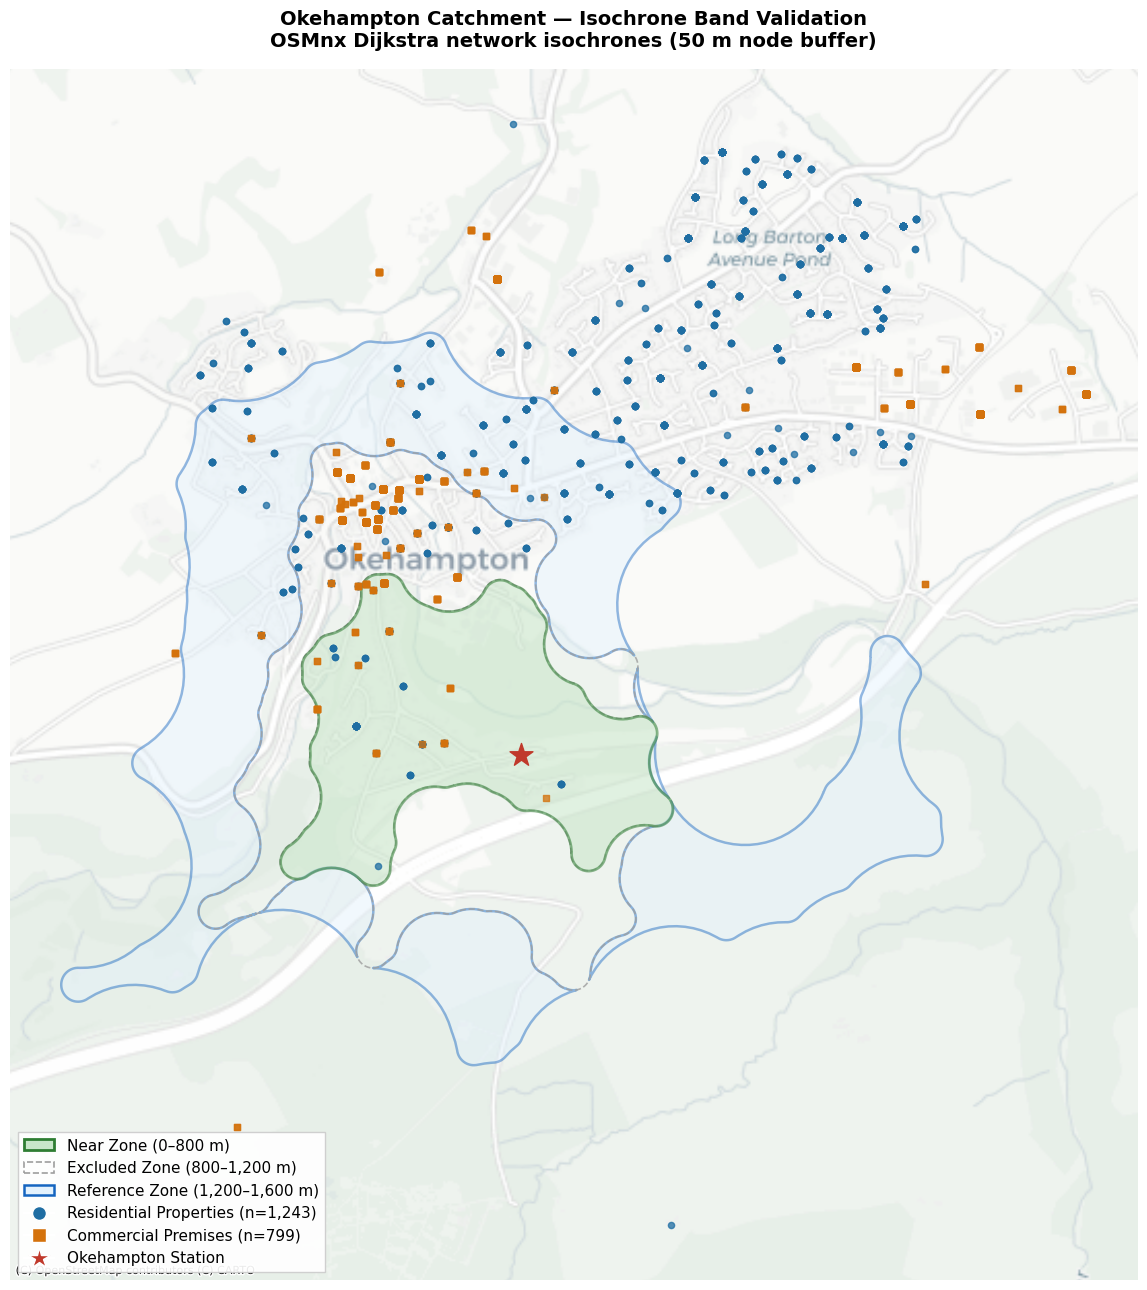

In [ ]:
# ==============================================================================
# VALIDATION: OKEHAMPTON CATCHMENT — ISOCHRONE BAND VISUAL CHECK
# ==============================================================================

%pip install contextily -q

import contextily as ctx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd
import pandas as pd
import os

BASE_DIR      = PROJECT_ROOT
ISO_PATH      = os.path.join(BASE_DIR, '02_processed_data/04_network/isochrone_bands.gpkg')
STATIONS_PATH = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')
RES_PATH      = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')
COMM_PATH     = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')

# ── load and filter to Okehampton ─────────────────────────────────────────────
gdf_iso    = gpd.read_file(ISO_PATH, layer='isochrone_bands')
gdf_iso_ok = gdf_iso[gdf_iso['Station'].str.contains('Okehampton', na=False)].copy()

gdf_station = gpd.read_file(STATIONS_PATH).to_crs("EPSG:27700")
gdf_ok_stn  = gdf_station[gdf_station['CommonName'].str.contains('Okehampton', na=False)].copy()

df_res     = pd.read_parquet(RES_PATH)
df_res_ok  = df_res[df_res['CommonName'].str.contains('Okehampton', na=False)].copy()
gdf_res_ok = gpd.GeoDataFrame(
    df_res_ok,
    geometry=gpd.points_from_xy(df_res_ok['east1m'], df_res_ok['north1m']),
    crs="EPSG:27700"
)

df_comm     = pd.read_parquet(COMM_PATH)
df_comm_ok  = df_comm[df_comm['CommonName'].str.contains('Okehampton', na=False)].copy()
gdf_comm_ok = gpd.GeoDataFrame(
    df_comm_ok,
    geometry=gpd.points_from_xy(df_comm_ok['east1m'], df_comm_ok['north1m']),
    crs="EPSG:27700"
)

# ── sanity check ──────────────────────────────────────────────────────────────
print("=" * 55)
print("OKEHAMPTON ISOCHRONE VALIDATION — SUMMARY")
print("=" * 55)
for _, band_row in gdf_iso_ok.sort_values('Inner_m').iterrows():
    print(f"  {band_row['Band']:<22} area: {band_row.geometry.area / 1e6:.3f} km²")

print(f"\n  Residential properties: {len(gdf_res_ok):,}")
if 'Distance_Band' in df_res_ok.columns:
    print(df_res_ok['Distance_Band'].value_counts().sort_index().to_string())

print(f"\n  Commercial premises:    {len(gdf_comm_ok):,}")
if 'Distance_Band' in df_comm_ok.columns:
    print(df_comm_ok['Distance_Band'].value_counts().sort_index().to_string())
print("=" * 55)

# ── reproject to Web Mercator for basemap ─────────────────────────────────────
WM = "EPSG:3857"
gdf_iso_wm  = gdf_iso_ok.to_crs(WM)
gdf_stn_wm  = gdf_ok_stn.to_crs(WM)
gdf_res_wm  = gdf_res_ok.to_crs(WM)
gdf_comm_wm = gdf_comm_ok.to_crs(WM)

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 13))

BAND_STYLE = {
    'Reference Zone': {'fc': '#E3F2FD', 'ec': '#1565C0', 'lw': 1.8,
                       'ls': '-',  'alpha': 0.45, 'zorder': 1},
    'Excluded Zone':  {'fc': 'none',    'ec': '#9E9E9E', 'lw': 1.2,
                       'ls': '--', 'alpha': 0.8,  'zorder': 2},
    'Near Zone':      {'fc': '#C8E6C9', 'ec': '#2E7D32', 'lw': 2.0,
                       'ls': '-',  'alpha': 0.55, 'zorder': 3},
}

for band_name, style in BAND_STYLE.items():
    subset = gdf_iso_wm[gdf_iso_wm['Band'] == band_name]
    if len(subset) == 0:
        print(f"WARNING: no features found for '{band_name}'")
        continue
    subset.plot(
        ax=ax, facecolor=style['fc'], edgecolor=style['ec'],
        linewidth=style['lw'], linestyle=style['ls'],
        alpha=style['alpha'], zorder=style['zorder']
    )

gdf_res_wm.plot(ax=ax, color='#1F6EA3', markersize=20,
                alpha=0.75, zorder=4, marker='o')
gdf_comm_wm.plot(ax=ax, color='#D4720C', markersize=22,
                 alpha=0.75, zorder=4, marker='s')
gdf_stn_wm.plot(ax=ax, color='#C0392B', markersize=300,
                zorder=6, marker='*')

try:
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, zoom=14)
except Exception:
    try:
        ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, zoom=14)
    except Exception as e:
        print(f"Basemap unavailable ({e}). Plotting without basemap.")

legend_handles = [
    mpatches.Patch(fc='#C8E6C9', ec='#2E7D32', lw=2.0,
                   label='Near Zone (0–800 m)'),
    mpatches.Patch(fc='none', ec='#9E9E9E', lw=1.2, ls='--',
                   label='Excluded Zone (800–1,200 m)'),
    mpatches.Patch(fc='#E3F2FD', ec='#1565C0', lw=1.8,
                   label='Reference Zone (1,200–1,600 m)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#1F6EA3',
               markersize=10, label=f'Residential Properties (n={len(gdf_res_ok):,})'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#D4720C',
               markersize=10, label=f'Commercial Premises (n={len(gdf_comm_ok):,})'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#C0392B',
               markersize=16, label='Okehampton Station'),
]

ax.legend(handles=legend_handles, loc='lower left', fontsize=11,
          framealpha=0.92, edgecolor='#CCCCCC', fancybox=False)
ax.set_title(
    'Okehampton Catchment — Isochrone Band Validation\n'
    'OSMnx Dijkstra network isochrones (50 m node buffer)',
    fontsize=14, fontweight='bold', pad=16
)
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# EXPORT RAIL NETWORK LINE FOR STATIC MASTER LAYER ASSEMBLY (QGIS DATABASE)
# ==============================================================================

import osmnx as ox
import geopandas as gpd

# Define study area
# Use the same 'place_name' or 'polygon' you used to get your street network
place_name = "Devon, England, UK"

# Download rail features
rail_network = ox.features_from_place(place_name, tags={'railway': 'rail'})

# Clean and Project
# Keep only LineStrings (sometimes OSM includes points for switches)
rail_lines = rail_network[rail_network.geom_type == 'LineString'].copy()
rail_lines = rail_lines.to_crs("EPSG:27700")

# Save to the network folder
output_path = os.path.join(BASE_DIR, '02_processed_data/04_network/rail_network_lines.gpkg')
rail_lines.to_file(output_path, driver="GPKG")

print(f"Rail network saved to: {output_path}")

Rail network saved to: /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/04_network/rail_network_lines.gpkg


In [ ]:
# ==============================================================================
# STATIC MASTER LAYER ASSEMBLY (QGIS DATABASE)
# ==============================================================================

import os
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Polygon

# Define paths
BASE_DIR = PROJECT_ROOT
OUTPUT_DB = os.path.join(BASE_DIR, '02_processed_data/static_master_layer.gpkg')

if not os.path.exists(BASE_DIR):
    print(f"\nCRITICAL ERROR: Colab cannot find the folder at {BASE_DIR}")
else:
    if os.path.exists(OUTPUT_DB):
        os.remove(OUTPUT_DB)

    print("\nInitialising Unified QGIS Masterlayer Assembly...\n")

    # Assemble Existing Layers - Pointing to the .parquet files for model-ready data
    layer_mapping = {
        '01_rail_network': os.path.join(BASE_DIR, '02_processed_data/04_network/rail_network_lines.gpkg'),
        '02_treatment_and_control_stations': os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg'),
        '02_pedestrian_routing_network': os.path.join(BASE_DIR, '02_processed_data/04_network/devon_walk_network.gpkg'),
        '02_isochrone_bands': os.path.join(BASE_DIR, '02_processed_data/04_network/isochrone_bands.gpkg'),
        '03_residential_points': os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet'),
        '03_commercial_points': os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')
    }

    # Tracking variable to control when to overwrite vs. when to append layers
    is_first_layer = True

    for layer_name, file_path in layer_mapping.items():
        if os.path.exists(file_path):
            print(f"Processing {layer_name}...")

            if layer_name == '03_residential_points':
                print("   -> Reading large residential dataset (this will take a couple of minutes, please wait)...")

            # Handle file reading and dynamic geometry recreation
            if file_path.endswith('.parquet'):
                df_temp = pd.read_parquet(file_path)
                gdf = gpd.GeoDataFrame(
                    df_temp,
                    geometry=gpd.points_from_xy(df_temp['east1m'], df_temp['north1m']),
                    crs="EPSG:27700"
                )
            elif layer_name == '02_pedestrian_routing_network':
                gdf = gpd.read_file(file_path, layer='edges')
            else:
                gdf = gpd.read_file(file_path)

            if gdf.crs != "EPSG:27700":
                gdf = gdf.to_crs("EPSG:27700")

            # Create the database with the first layer, then append all subsequent layers
            write_mode = 'w' if is_first_layer else 'a'
            gdf.to_file(OUTPUT_DB, layer=layer_name, driver='GPKG', mode=write_mode)
            is_first_layer = False
            print(f"   -> Done writing {layer_name}.")
        else:
            print(f"   -> ERROR: File not found: {file_path}")

    # Process raw boundary data
    print("\nProcessing 01_devon_boundary...")
    boundary_path = os.path.join(BASE_DIR, '02_processed_data/Devon_Geography_Boundary_File.geojson')

    if os.path.exists(boundary_path):
        gdf_boundary = gpd.read_file(boundary_path).to_crs("EPSG:27700")

        # Append to the database instead of overwriting it
        gdf_boundary.to_file(OUTPUT_DB, layer='01_devon_boundary', driver='GPKG', mode='a')
        print("   -> Done writing 01_devon_boundary.")
    else:
        print(f"   -> ERROR: Boundary file not found: {boundary_path}")

    # Generate market liquidity grid
    # Market liquidity is how quickly an asset (a house) can be converted into cash (sold) without affecting its market price.
    print("\nGenerating 04_market_liquidity_hexgrid...")
    res_path = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')

    if os.path.exists(res_path):
        # Read the parquet and reconstruct geometry for spatial join
        df_res = pd.read_parquet(res_path)
        gdf_res = gpd.GeoDataFrame(
            df_res,
            geometry=gpd.points_from_xy(df_res['east1m'], df_res['north1m']),
            crs="EPSG:27700"
        )

        grid_size = 1000
        # Use the bounds of the ACTUAL data to ensure Plymouth is captured
        xmin, ymin, xmax, ymax = gdf_res.total_bounds
        cols = list(np.arange(xmin, xmax + grid_size, grid_size))
        rows = list(np.arange(ymin, ymax + grid_size, grid_size))

        polygons = []
        for x in cols[:-1]:
            for y in rows[:-1]:
                polygons.append(Polygon([(x,y), (x+grid_size, y), (x+grid_size, y+grid_size), (x, y+grid_size)]))

        grid = gpd.GeoDataFrame({'geometry': polygons}, crs="EPSG:27700")
        # Join properties to the grid
        joined = gpd.sjoin(gdf_res, grid, how="inner", predicate="intersects")

        # Calculate sizes and perfectly map to grid index
        liquidity_counts = joined.groupby('index_right').size()
        grid['transaction_count'] = grid.index.map(liquidity_counts).fillna(0).astype(int)

        # Drop all empty grid cells
        grid = grid[grid['transaction_count'] > 0]

        # Append the final grid layer safely
        grid.to_file(OUTPUT_DB, layer='04_market_liquidity_hexgrid', driver='GPKG', mode='a')
        print("   -> Done generating market liquidity grid.")
    else:
        print("   -> ERROR: Missing residential parquet file for grid generation.")

    print(f"\n✅ Script 4 Complete: QGIS Masterlayer successfully built at: {OUTPUT_DB}")
    print("   Status: All layers written concurrently. 01_lsoa_imd integrated directly into residential attribute tables.")


Initialising Unified QGIS Masterlayer Assembly...

Processing 01_rail_network...
   -> Done writing 01_rail_network.
Processing 02_treatment_and_control_stations...
   -> Done writing 02_treatment_and_control_stations.
Processing 02_pedestrian_routing_network...
   -> Done writing 02_pedestrian_routing_network.
Processing 02_isochrone_bands...
   -> Done writing 02_isochrone_bands.
Processing 03_residential_points...
   -> Reading large residential dataset (this will take a couple of minutes, please wait)...
   -> Done writing 03_residential_points.
Processing 03_commercial_points...
   -> Done writing 03_commercial_points.

Processing 01_devon_boundary...
   -> Done writing 01_devon_boundary.

Generating 04_market_liquidity_hexgrid...
   -> Done generating market liquidity grid.

✅ Script 4 Complete: QGIS Masterlayer successfully built at: /content/drive/MyDrive/MSc_Dissertation_Project/02_processed_data/static_master_layer.gpkg
   Status: All layers written concurrently. 01_lsoa_imd

In [ ]:
# ==============================================================================
# REVEAL THE ATTRITION LOG
# ==============================================================================
import json
import pandas as pd
import os

# Define the path to your log
attrition_path = os.path.join(PROJECT_ROOT, '05_logs/script_logs/attrition_log.json')

if os.path.exists(attrition_path):
    with open(attrition_path, 'r') as f:
        log_data = json.load(f)

    # Convert to DataFrame for a clean view
    # orient='index' treats the main keys (timestamped events) as rows
    df_logs = pd.DataFrame.from_dict(log_data, orient='index')

    # Display the full table
    pd.set_option('display.max_colwidth', None) # Show full notes
    print("==================================================")
    print("DATA ATTRITION LOG SUMMARY")
    print("==================================================")
    print(df_logs)

    # Optional: Save to CSV for your thesis write-up
    # df_logs.to_csv(os.path.join(os.path.dirname(attrition_path), 'attrition_summary.csv'))
    # print("\n✅ Exported log summary to CSV for your dissertation document.")
else:
    print("Log file not found at the specified path.")

DATA ATTRITION LOG SUMMARY
                                                               01_Raw_National_Rows  02_Devon_Filtered_Rows  03_HPI_Matched_Rows  03a_Category_A_Filtered_Rows  03b_Outlier_Filtered_Rows  04_De-duplicated_Rows  03_Final_Devon_Rows  04_Initial_Stacked_Panel  05_Zero_Filtered_Panel                                                                                                                                                                                                                                                                                                                                                       Note  01_Input_Residential_Rows  02_Matched_UPRN_Rows  03_Match_Rate_Percent                                                                                               04_Property_Type_Breakdown  02_Geocoded_Point_Rows  03_Final_Buffered_Rows  04_Retention_Rate_Percent  01_Input_Commercial_Rows  01_Input_Properties  02_LSOA_Matched  03_Properties

In [ ]:
# ==============================================================================
# VERIFICATION: CHECKING THE STATISTICS OF PROPERTY AND PREMISES DISTRIBUTION
# ==============================================================================

import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

BASE = os.path.join(PROJECT_ROOT, '02_processed_data/03_model_ready/')
band_order = ['0-400m', '400-800m', '800-1200m', '1200-1600m']

def treat(df):
    df['Treated'] = df['CommonName'].str.contains('Marsh Barton|Okehampton', na=False).astype(int)
    return df

def in_catchment(df):
    c = df[df['Distance_Band'].astype(str) != '1600m+'].copy()
    c['Distance_Band'] = pd.Categorical(c['Distance_Band'].astype(str), categories=band_order, ordered=True)
    return c

# ===== RESIDENTIAL (primary causal) =====
res = treat(pd.read_parquet(BASE + 'regression_ready_residential.parquet'))
print('=' * 72)
print('RESIDENTIAL - design sizing')
print('=' * 72)
print('Total rows:', len(res), '\n')

print('--- Transactions per station (treated=1 are Marsh Barton / Okehampton) ---')
print(res.groupby('CommonName').agg(n=('Transaction_ID', 'size'), treated=('Treated', 'max')).sort_values('n', ascending=False), '\n')

print('--- Treated x Epoch (full sample, incl. 1600m+) ---')
print(pd.crosstab(res['Treated'], res['Epoch']), '\n')

rcat = in_catchment(res)
print('--- In-catchment N (0-1600m only):', len(rcat), '---\n')
print('--- Treated x Distance_Band x Epoch (in-catchment) ---')
print(pd.crosstab([rcat['Treated'], rcat['Distance_Band']], rcat['Epoch']), '\n')

print('--- KEY DiD CELLS: Treated x band x {Baseline, Operational} only ---')
key = rcat[rcat['Epoch'].isin(['Baseline', 'Operational'])]
print(pd.crosstab([key['Treated'], key['Distance_Band']], key['Epoch']))

# ===== COMMERCIAL (secondary, exploratory, anticipation) =====
com = treat(pd.read_parquet(BASE + 'regression_ready_commercial.parquet'))
print('\n' + '=' * 72)
print('COMMERCIAL - design sizing (exploratory / anticipation)')
print('=' * 72)
print('Total rows:', len(com), '| Epochs:', dict(com['Epoch'].value_counts()), '\n')

yrs = com.groupby('Assessment_UARN')['Year'].nunique()
print('Unique assessments:', com['Assessment_UARN'].nunique())
print('Assessments in BOTH 2017 & 2023:', int((yrs == 2).sum()), '(', round((yrs == 2).mean() * 100, 1), '%) - supports entity FE if high\n')

print('--- Treated x Epoch (full sample) ---')
print(pd.crosstab(com['Treated'], com['Epoch']), '\n')

ccat = in_catchment(com)
print('--- In-catchment N (0-1600m only):', len(ccat), '---\n')
print('--- Treated x Distance_Band x Epoch (in-catchment) ---')
print(pd.crosstab([ccat['Treated'], ccat['Distance_Band']], ccat['Epoch']))

RESIDENTIAL - design sizing
Total rows: 31883 

--- Transactions per station (treated=1 are Marsh Barton / Okehampton) ---
                                          n  treated
CommonName                                          
Devonport Rail Station                 4676        0
Exeter St Thomas Rail Station          4300        0
Torre Rail Station                     3637        0
Pinhoe Rail Station                    3552        0
Paignton Rail Station                  3200        0
St Budeaux Victoria Road Rail Station  2626        0
Barnstaple Rail Station                2514        0
Digby & Sowton Rail Station            2397        0
Marsh Barton Rail Station              1493        1
Honiton Rail Station                   1404        0
Okehampton Rail Station                1243        1
Crediton Rail Station                   841        0 

--- Treated x Epoch (full sample, incl. 1600m+) ---
Epoch    Announcement  Baseline  Construction  Operational
Treated               

In [3]:
# ==============================================================================
# VERIFICATION: Digby & Sowton distance band distribution
# ==============================================================================
import pandas as pd
import os

BASE_DIR = PROJECT_ROOT

RES_PATH  = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')
COMM_PATH = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')

res  = pd.read_parquet(RES_PATH)
comm = pd.read_parquet(COMM_PATH)

res['Station']  = res['CommonName'].str.replace(' Rail Station', '', regex=False).str.strip()
comm['Station'] = comm['CommonName'].str.replace(' Rail Station', '', regex=False).str.strip()

digby_res  = res[res['Station']  == 'Digby & Sowton']
digby_comm = comm[comm['Station'] == 'Digby & Sowton']

print("=" * 60)
print("RESIDENTIAL — Digby & Sowton")
print("=" * 60)
print(f"Total rows assigned to this station: {len(digby_res)}")
print(f"\nDistance band distribution:")
print(digby_res['Distance_Band'].value_counts().sort_index())
print(f"\nIn-catchment (0-1600m): {(digby_res['Distance_Band'] != '1600m+').sum()}")
print(f"Out of catchment (1600m+): {(digby_res['Distance_Band'] == '1600m+').sum()}")
print(f"\nMin walking distance (m): {digby_res['walk_dist_m'].min():.1f}")
print(f"Max walking distance (m): {digby_res['walk_dist_m'].max():.1f}")
print(f"Mean walking distance (m): {digby_res['walk_dist_m'].mean():.1f}")

print()
print("=" * 60)
print("COMMERCIAL — Digby & Sowton")
print("=" * 60)
print(f"Total rows assigned to this station: {len(digby_comm)}")
print(f"\nDistance band distribution:")
print(digby_comm['Distance_Band'].value_counts().sort_index())
print(f"\nIn-catchment (0-1600m): {(digby_comm['Distance_Band'] != '1600m+').sum()}")
print(f"Out of catchment (1600m+): {(digby_comm['Distance_Band'] == '1600m+').sum()}")
if len(digby_comm) > 0 and 'walk_dist_m' in digby_comm.columns:
    print(f"\nMin walking distance (m): {digby_comm['walk_dist_m'].min():.1f}")
    print(f"Max walking distance (m): {digby_comm['walk_dist_m'].max():.1f}")
    print(f"Mean walking distance (m): {digby_comm['walk_dist_m'].mean():.1f}")

RESIDENTIAL — Digby & Sowton
Total rows assigned to this station: 2397

Distance band distribution:
Distance_Band
0-400m           0
400-800m         0
800-1200m        0
1200-1600m       0
1600m+        2397
Name: count, dtype: int64

In-catchment (0-1600m): 0
Out of catchment (1600m+): 2397

Min walking distance (m): 2365.0
Max walking distance (m): 9656.8
Mean walking distance (m): 5342.8

COMMERCIAL — Digby & Sowton
Total rows assigned to this station: 1733

Distance band distribution:
Distance_Band
0-400m           0
400-800m         0
800-1200m        0
1200-1600m       0
1600m+        1733
Name: count, dtype: int64

In-catchment (0-1600m): 0
Out of catchment (1600m+): 1733

Min walking distance (m): 3296.3
Max walking distance (m): 8857.9
Mean walking distance (m): 5796.9
